In [6]:

import os
import warnings
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from ladcp_tools import *                  # load_all_stations, ...
from tools import *                        # load_satellite, load_eddies, plot_eddies, setup_map


In [7]:
lon_min, lon_max, lat_min, lat_max = 8, 25, -41, -34
extent = [lon_min, lon_max, lat_min, lat_max]

CRUISE_START = "2026-05-14"
CRUISE_END   = "2026-07-27"

ft = 10
vmin, vmax = -1.5, 1.5
levels = np.arange(vmin, vmax + 0.01, 0.01)

BASE = Path("/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS")
DIR_SADCP = BASE / "data/SADCP"
SADCP_FILES = {"OS150": DIR_SADCP / "WHIRLS_NB150_TOT_osite.nc",   # full cruise (README)
               "OS38": DIR_SADCP / "WHIRLS_BB38_TOT_osite.nc"}
DIR_LADCP = BASE / "data/LADCP/traitement_avec_SADCP"
DIR_SSH = BASE / "data/SSH"
DIR_EDDIES = {"TOEDDIES_better_ADT": BASE / "data/TOEDDIES/TOEDDIES_better_ADT",
              "TOEDDIES": BASE / "data/TOEDDIES/TOEDDIES"}
FNAME_BATHY = BASE / "data/bathymetry/etopo2.nc"
DIR_TRACKS = BASE / "figures/eddy_tracks"
DIR_CODE = BASE / "analysis"          # where ladcp_tools.py lives

FRAME_DIR = "whirls_eddies_animation"
OUT_MP4   = "whirls_eddies_animation.mp4"
FPS = 2                                   # frames (days) per second

os.makedirs(FRAME_DIR, exist_ok=True)

crs = ccrs.PlateCarree()
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max) / 2)

# ----------------------------------------------------------------------------
# Things loaded ONCE (they don't change from day to day)
# ----------------------------------------------------------------------------
# Bathymetry
bathymetry_data = xr.open_dataset(FNAME_BATHY)
lon_subset = bathymetry_data["lon"].sel(lon=slice(lon_min, lon_max))
lat_subset = bathymetry_data["lat"].sel(lat=slice(lat_min, lat_max))
depth_subset = bathymetry_data["topo"].sel(lon=slice(lon_min, lon_max),
                                           lat=slice(lat_min, lat_max))

# File lists
daily_ssh_files = sorted(os.listdir(DIR_SSH))
eddy_files_better = sorted(os.listdir(DIR_EDDIES['TOEDDIES_better_ADT']))
eddy_files_std = sorted(os.listdir(DIR_EDDIES['TOEDDIES']))


def get_eddy_files(date_compact, date):
    """Use the better-ADT TOEddies when available for that day, else the standard ones."""
    files = [DIR_EDDIES['TOEDDIES_better_ADT'] / f for f in eddy_files_better if date_compact in f]
    if files:
        return files, "TOEddies (better ADT)"
    files = [DIR_EDDIES['TOEDDIES'] / f for f in eddy_files_std if date in f]
    if files:
        return files, "TOEddies (standard)"
    return [], None


def find_time_column(df):
    """Return the name of the column holding the cast time."""
    for cand in ["time", "date", "datetime", "start_time", "time_start", "t"]:
        if cand in df.columns:
            return cand
    for c in df.columns:                       # any datetime-typed column
        if np.issubdtype(df[c].dtype, np.datetime64):
            return c
    raise KeyError(
        "No time column found in the LADCP station table. "
        f"Columns are: {list(df.columns)}. "
        "Add the cast time in load_all_stations() or set TIME_COL by hand."
    )


# TIME_COL = find_time_column(st)
# st["day"] = pd.to_datetime(st[TIME_COL]).dt.normalize()


In [8]:
def label_eddies(ax, eddies, color, extent, crs, tag):
    """Write each eddy's index at its center and print it with its position."""
    cen = eddies.get("centers")
    if cen is None:
        return
    x0, x1, y0, y1 = extent
    for i, p in enumerate(cen.geometry):          # i = position in the file
        if p is None or p.is_empty:
            continue
        lon, lat = p.x, p.y
        if not (x0 <= lon <= x1 and y0 <= lat <= y1):
            continue                               # only eddies on the map
        ax.text(lon, lat, str(i), transform=crs, fontsize=6, color=color,
                weight="bold", ha="center", va="center", zorder=105,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec=color,
                          lw=0.5, alpha=0.85))
        print(f"{tag} #{i:<4} START_LON, START_LAT = {lon:.3f}, {lat:.3f}")

AE #9    START_LON, START_LAT = 8.438, -40.188
AE #10   START_LON, START_LAT = 21.812, -39.312
AE #11   START_LON, START_LAT = 11.688, -39.187
AE #12   START_LON, START_LAT = 16.562, -38.562
AE #13   START_LON, START_LAT = 23.437, -37.812
AE #14   START_LON, START_LAT = 19.062, -36.688
AE #15   START_LON, START_LAT = 9.312, -36.562
AE #16   START_LON, START_LAT = 12.812, -34.938
CE #9    START_LON, START_LAT = 19.562, -40.938
CE #10   START_LON, START_LAT = 10.312, -40.812
CE #12   START_LON, START_LAT = 15.187, -40.188
CE #13   START_LON, START_LAT = 24.312, -39.812
CE #14   START_LON, START_LAT = 8.812, -38.562
CE #16   START_LON, START_LAT = 18.938, -37.938
CE #17   START_LON, START_LAT = 11.312, -37.562
CE #18   START_LON, START_LAT = 17.312, -36.562
CE #19   START_LON, START_LAT = 13.062, -36.438
CE #21   START_LON, START_LAT = 15.062, -35.938
CE #22   START_LON, START_LAT = 8.438, -35.312
CE #23   START_LON, START_LAT = 20.437, -35.188
CE #24   START_LON, START_LAT = 18.437, -34.

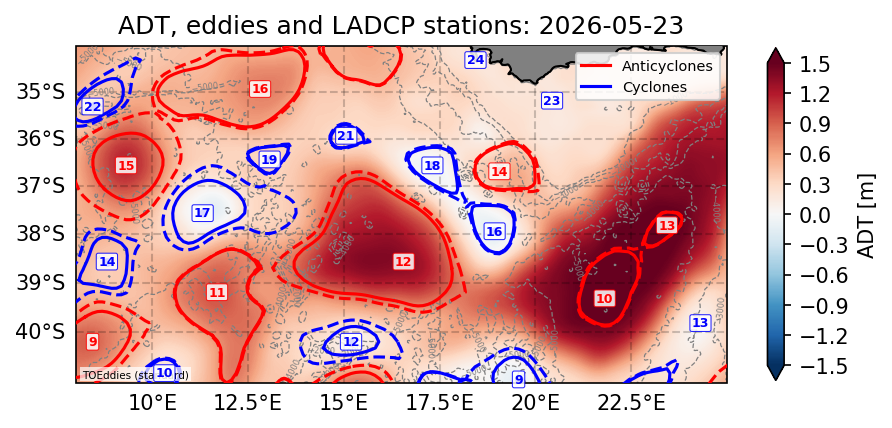

In [15]:
date = "2026-05-23"
date_str = date
date_compact = date.replace("-", "")

# --- ADT of the day ---
ssh_match = [f for f in daily_ssh_files if date_str in f or date_compact in f]

ssh = load_satellite(DIR_SSH / ssh_match[0])

# --- Eddies of the day ---
eddy_files, eddy_source = get_eddy_files(date_compact, date_str)

# Fixed figure size and no bbox_inches="tight" so all frames are identical in size
fig = plt.figure(figsize=(7, 4.8), dpi=150)
ax = fig.add_subplot(111, projection=proj)
setup_map(ax, extent, f"ADT, eddies and LADCP stations: {date_str}", crs, ft)

bathy = ax.contour(lon_subset, lat_subset, depth_subset,
                    colors="grey", linewidths=0.6, transform=crs)
ax.clabel(bathy, fontsize=4)

c = ax.contourf(ssh["lon"], ssh["lat"], ssh["adt"][0],
                levels=levels, cmap="RdBu_r", extend="both",
                transform=crs)

if eddy_files:
    anti, cyc = load_eddies(eddy_files)
    plot_eddies(ax, anti, "red", crs)
    plot_eddies(ax, cyc, "blue", crs)
    label_eddies(ax, anti, "red", extent, crs, "AE")
    label_eddies(ax, cyc, "blue", extent, crs, "CE")
else:
    warnings.warn(f"No eddy file for {date_str} in either TOEddies folder.")

# Small label so you can see which eddy product each frame uses
if eddy_source:
    ax.text(0.01, 0.01, eddy_source, transform=ax.transAxes, fontsize=5,
            ha="left", va="bottom", zorder=102,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1))

# --- Legend (proxy handles, so it is the same on every frame) ---
handles = [
    mlines.Line2D([], [], color="red", label="Anticyclones"),
    mlines.Line2D([], [], color="blue", label="Cyclones"),
]
ax.legend(handles=handles, fontsize="x-small", loc="upper right",
            framealpha=0.85)

cb = fig.colorbar(c, ax=ax, shrink=0.6, ticks=np.arange(vmin, vmax + 0.01, 0.3))
cb.set_label("ADT [m]")
plt.show()
